# Phân loại bình luận Toxic bằng PhoBERT (v2)

Notebook này **fine-tune PhoBERT** (`vinai/phobert-base-v2`), mô hình BERT tiếng Việt được học trước trên 20 GB văn bản tiếng Việt từ VinAI, để phân loại bình luận sản phẩm thành **toxic (1)** hoặc **không toxic (0)**.

**Quy chuẩn dự án:** Notebook sử dụng dữ liệu từ thư mục `data/` (`train.csv`, `val.csv`, `test.csv`) và tự động xuất các file dự đoán chuẩn hóa phục vụ TV4:
- `results/predictions/phobert.csv`
- `results/predictions/phobert_info.json`

Các file này tương thích hoàn toàn để chạy đối sánh trực tiếp với Naive Bayes và Linear SVM bằng script `4_model_evaluation.py`.

## 1. Cài đặt thư viện
Trên Kaggle và Colab, torch và transformers đã có sẵn, cell này chủ yếu cài thêm `pyvi` (dùng để tách từ tiếng Việt, không cần Java). Cần bật **Internet: On** trong Settings của notebook.

In [1]:
# Cài đặt các thư viện cần thiết
%pip install -q transformers pyvi scikit-learn pandas matplotlib tabulate accelerate
# Nếu chưa có PyTorch: xem hướng dẫn cài đặt phù hợp với máy tại https://pytorch.org/get-started/locally/


### Hướng dẫn chạy cho tất cả thành viên trong nhóm:

#### 1. Chạy trên Google Colab (Khuyên dùng - Đơn giản nhất, GPU T4 miễn phí):
1. Mở notebook này trên Google Colab.
2. Bật GPU: Vào menu **Runtime** (Thời lượng chạy) -> **Change runtime type** (Thay đổi loại thời lượng chạy) -> Chọn **T4 GPU** -> Bấm **Save** (Lưu).
3. Dữ liệu: Kéo thả thư mục `data` (chứa `train.csv`, `val.csv`, `test.csv`) vào khung **Files** (biểu tượng thư mục bên trái). Notebook sẽ tự động nhận diện dữ liệu.
4. Chạy mô hình: Chọn menu **Runtime** -> **Run all** (Chạy tất cả). Cuối notebook sẽ tự động nén và tải file zip kết quả về máy.

#### 2. Chạy trên Kaggle (GPU T4 x2):
1. Tạo notebook mới trên Kaggle, tải file này lên.
2. Nhấn **Add Input** ở góc phải -> Tải lên thư mục `data/`.
3. Ở bảng **Settings** bên phải: **Accelerator** chọn **GPU T4 x2**, **Internet** gạt sang **On**.
4. Bấm **Save Version -> Save & Run All (Commit)** hoặc chạy từng cell.

#### 3. Chạy trên máy cá nhân (Local):
1. Mở trực tiếp bằng VS Code hoặc Jupyter Notebook trong thư mục dự án.
2. Notebook tự động dò thấy thư mục `data/` và xuất kết quả vào `results/`.
*(Lưu ý: Nếu máy không có card đồ họa NVIDIA, notebook sẽ chạy trên CPU. Khuyên bật `QUICK_TEST = True` ở mục 2 nếu chỉ muốn kiểm tra code)*.

In [2]:
import os, glob
import pandas as pd

DATA_DIR_OVERRIDE = None

# 1. Phát hiện môi trường Kaggle
if os.path.isdir("/kaggle/input"):
    cands = sorted(os.path.dirname(p) for p in glob.glob("/kaggle/input/**/train.csv", recursive=True)
                   if all(os.path.exists(os.path.join(os.path.dirname(p), f)) for f in ("val.csv", "test.csv")))
    if cands:
        cands.sort(key=lambda d: ("data" not in d.lower() and "nlp" not in d.lower()))
        DATA_DIR_OVERRIDE = cands[0]
        print(f"👉 Tìm thấy dữ liệu trên Kaggle: {DATA_DIR_OVERRIDE}")

    local_bpe = glob.glob("/kaggle/input/**/bpe.codes", recursive=True)
    if local_bpe:
        os.environ["PHOBERT_MODEL"] = os.path.dirname(local_bpe[0])
        print(f"👉 Mô hình PhoBERT offline: {os.environ['PHOBERT_MODEL']}")

# 2. Phát hiện môi trường Google Colab / Local
if DATA_DIR_OVERRIDE is None:
    candidate_paths = [
        "data",
        "./data",
        "../data",
        "/content/data",
        "/content/vanban_btl1/data",
        "/content/drive/MyDrive/data",
        os.path.join(os.getcwd(), "data"),
    ]
    for p in candidate_paths:
        if os.path.exists(os.path.join(p, "train.csv")) and os.path.exists(os.path.join(p, "test.csv")):
            DATA_DIR_OVERRIDE = p
            print(f"👉 Tìm thấy dữ liệu tại: {DATA_DIR_OVERRIDE}")
            break

# 3. Tìm kiếm đệ quy dự phòng
if DATA_DIR_OVERRIDE is None:
    found = [os.path.dirname(p) for p in glob.glob("**/train.csv", recursive=True)
             if os.path.exists(os.path.join(os.path.dirname(p), "test.csv"))]
    if found:
        DATA_DIR_OVERRIDE = found[0]
        print(f"👉 Tự động dò thấy dữ liệu tại: {DATA_DIR_OVERRIDE}")
    else:
        print("⚠️ Chưa tìm thấy thư mục chứa train.csv và test.csv!")
        print("👉 Nếu bạn đang chạy trên Google Colab, hãy kéo thả thư mục 'data' vào khung Files bên trái.")


👉 Tìm thấy dữ liệu tại: data


## 2. Cấu hình

In [3]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Xác định đường dẫn gốc dự án
ROOT       = ".." if os.path.exists("../4_model_evaluation.py") else "."
DATA_DIR   = globals().get("DATA_DIR_OVERRIDE") or os.path.join(ROOT, "data")
OUT_DIR    = os.path.join(ROOT, "results", "phobert_v2")
PRED_DIR   = os.path.join(ROOT, "results", "predictions")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)

MODEL_NAME = os.environ.get("PHOBERT_MODEL") or ("models/phobert-base-v2" if os.path.isdir("models/phobert-base-v2") else "vinai/phobert-base-v2")

INPUT_MODE = "pyvi"
NORMALIZE_TEENCODE = True
TEXT_COL   = "text_seg"

def pick_device():
    if torch.cuda.is_available(): return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available(): return torch.device("mps")
    return torch.device("cpu")

DEVICE  = pick_device()
USE_AMP = DEVICE.type == "cuda"

# Siêu tham số huấn luyện
SEEDS      = [42, 13, 7]          # Chạy 3 seed để lấy kết quả trung bình khách quan
EPOCHS     = 5
BATCH_SIZE = 16                   # Nếu báo tràn VRAM GPU thì giảm xuống 8
LR         = 2e-5
WARMUP     = 0.1
MAX_POS_WEIGHT = 10.0
PATIENCE   = 2                    # Early stopping: dừng nếu sau 2 epoch PR-AUC val không tăng
MAX_LEN    = 256 if DEVICE.type == "cuda" else 128
QUICK_TEST = False                # Đặt True nếu muốn chạy test nhanh 1 epoch để thử code
SAVE_MODEL = True
MEASURE_CPU_LATENCY = True
N_CPU_LATENCY = 200

if DEVICE.type == "cpu":
    print("=" * 65)
    print("⚠️ CẢNH BÁO: BẠN ĐANG CHẠY TRÊN CPU!")
    print("- Fine-tuning PhoBERT trên CPU sẽ mất khoảng 1-2 tiếng.")
    print("- Khuyên dùng GPU: Trên Colab chọn Runtime -> Change runtime type -> T4 GPU.")
    print("- Nếu chỉ muốn kiểm tra chạy thử code, hãy đặt QUICK_TEST = True bên dưới.")
    print("=" * 65)

if QUICK_TEST:
    EPOCHS, MAX_LEN, SEEDS = 1, 64, SEEDS[:1]
    print("⚡ Chế độ QUICK_TEST được bật: 1 seed, 1 epoch để kiểm tra nhanh.")

print(f"📁 Dữ liệu: {DATA_DIR} | Kết quả: {OUT_DIR} | File nộp TV4: {PRED_DIR}")
print(f"🤖 Mô hình: {MODEL_NAME}")
print(f"⚙️ Thiết bị: {DEVICE} | torch {torch.__version__} | max_len {MAX_LEN} | epochs {EPOCHS} | seeds {SEEDS}")
if DEVICE.type == "cuda":
    print(f"🚀 GPU: {torch.cuda.get_device_name(0)}")

import sys, platform, sklearn, transformers
from importlib import metadata as _md
def _ver(pkg):
    try: return _md.version(pkg)
    except Exception: return None
ENV = {
    "nen_tang": "Colab" if "google.colab" in sys.modules else ("Kaggle" if os.path.isdir("/kaggle") else platform.platform()),
    "python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
    "scikit_learn": sklearn.__version__, "pyvi": _ver("pyvi"), "thiet_bi": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "so_luong_cpu": os.cpu_count()
}
print("Môi trường:", ENV)


📁 Dữ liệu: data | Kết quả: ./results/phobert_v2 | File nộp TV4: ./results/predictions
🤖 Mô hình: vinai/phobert-base-v2
⚙️ Thiết bị: cuda | torch 2.11.0+cu130 | max_len 256 | epochs 5 | seeds [42, 13, 7]
🚀 GPU: Tesla T4
Môi trường: {'nen_tang': 'Colab', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.22.0', 'scikit_learn': '1.6.1', 'pyvi': '0.1.1', 'thiet_bi': 'cuda', 'gpu': 'Tesla T4', 'so_luong_cpu': 2}


## 3. Đọc và khám phá dữ liệu

In [4]:
def read(name):
    path = os.path.join(DATA_DIR, f"{name}.csv")
    assert os.path.exists(path), f"Không tìm thấy file {path}! Vui lòng kiểm tra lại đường dẫn DATA_DIR."
    d = pd.read_csv(path, encoding="utf-8-sig")
    for c in ("noi_dung_goc", "noi_dung_tien_xu_ly"):
        if c in d.columns:
            d[c] = d[c].fillna("").astype(str)
        else:
            d[c] = ""
    d["label"] = d["label"].astype(int)
    return d

train_df, val_df, test_df = read("train"), read("val"), read("test")
assert len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0, "Dữ liệu không được để trống!"

summary = pd.DataFrame({
    "Số câu":  [len(d) for d in (train_df, val_df, test_df)],
    "Toxic":   [int(d.label.sum()) for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"])
summary["% toxic"] = (summary["Toxic"] / summary["Số câu"] * 100).round(2)
print("✅ Nạp dữ liệu thành công:")
display(summary)


✅ Nạp dữ liệu thành công:


,Số câu,Toxic,% toxic
train,7011,301,4.29
val,997,45,4.51
test,1992,80,4.02


In [5]:
print('Ví dụ câu toxic:')
for s in train_df[train_df.label == 1]['noi_dung_goc'].sample(5, random_state=1):
    print(' -', s[:150])

Ví dụ câu toxic:
 - Mua về là hư luôn, bấp nấu nồi canh th 2 núm vặn nóg hơn cục lửa k đụng vào được s tắt, dt tong đài 3 lần moiw chịu xuống ktra, kỷa xong nói chờ hãng 
 - Loa 20W. Nghe, kiểu dáng Ngang Con 5W.. pin 18H . Nghe 1H... Lừa Đảo.. Trả lại thì Mất Tiền nhiều.. trừ % Cao
 - nghỉ làm sao tụi tôi đi làm từ sáng tới tối mới về mà NV giao hàng bảo là CẦN PHẢI XÁC NHẬN ĐƠN, NÊN PHẢI GIAO NGAY BÂY GIỜ, NGÀY NÀO CŨNG ĐI LÀM HẾT 
 - Cực kỳ tệ các bạn đừng mua nhé, tất cả đồ của điện máy tốt nhất nên cân nhắc trước khi mua, tránh trước hoạ vào thân giống như mình
 - Rất thất vọng và bực mình, cảm giác như bị lừa đảo Về sản phẩm Quá tệ Mình mua máy mới mà cứ bật chế độ nóng lên là vòi nước nóng chảy ra đầy nhà, bên


## 4. Tách từ cho PhoBERT

PhoBERT được học trên văn bản đã tách từ, trong đó các âm tiết của một từ được nối bằng dấu gạch dưới (ví dụ `bảo hành` thành `bảo_hành`). Mục này tạo cột `text_seg` theo `INPUT_MODE` đã chọn:

- **`'pyvi'` (mặc định):** chuẩn hoá Unicode và một số teencode, rồi tách từ văn bản gốc bằng pyvi. Cách này giữ lại các tín hiệu toxic như chữ hoa, dấu "!" và từ lóng.
- **`'tien_xu_ly'`:** dùng cột `noi_dung_tien_xu_ly` có sẵn. Cột này đã viết thường và bỏ stopword nên mất một phần tín hiệu.

Tác giả PhoBERT dùng VnCoreNLP (cần Java) để tách từ. Notebook dùng pyvi vì dễ cài hơn; kết quả tách từ giữa hai công cụ có thể khác nhau đôi chút. **Câu mới khi dự đoán cũng phải đi qua đúng hàm `segment()` này.**

In [6]:
import re, unicodedata
from pyvi import ViTokenizer

TEENCODE = {'ko': 'không', 'k': 'không', 'kh': 'không', 'hk': 'không', 'khong': 'không', 'dc': 'được', 'đc': 'được',
            'ok': 'ổn', 'oke': 'ổn', 'okie': 'ổn', 'sp': 'sản phẩm', 'nv': 'nhân viên', 'bh': 'bảo hành',
            'mn': 'mọi người', 'j': 'gì', 'dt': 'điện thoại', 'đt': 'điện thoại', 'r': 'rồi', 'z': 'vậy',
            'dmx': 'điện máy xanh', 'đmx': 'điện máy xanh', 'tgdd': 'thế giới di động', 'tgdđ': 'thế giới di động'}

def split_glued(s):
    # "thôiBỏ" -> "thôi Bỏ": chữ thường/số dính liền chữ hoa (thường do các câu bị nối khi thu thập dữ liệu)
    out = []
    for i, ch in enumerate(s):
        if i and ch.isupper() and (s[i - 1].islower() or s[i - 1].isdigit()):
            out.append(' ')
        out.append(ch)
    return ''.join(out)

def normalize(s):
    s = unicodedata.normalize('NFC', s)
    s = split_glued(s)
    s = re.sub(r'(?<=[^\W\d_])([.,!?;:]+)(?=[^\W\d_])', r'\1 ', s)   # "tốt.Giao" -> "tốt. Giao"
    s = re.sub(r'\s+', ' ', s).strip()
    if NORMALIZE_TEENCODE:
        s = ' '.join(TEENCODE.get(w.lower(), w) for w in s.split(' '))
    return s

def segment(text):
    if INPUT_MODE == 'tien_xu_ly':
        return text                      # cột có sẵn đã được tách từ
    return ViTokenizer.tokenize(normalize(text))

src = 'noi_dung_tien_xu_ly' if INPUT_MODE == 'tien_xu_ly' else 'noi_dung_goc'
t0 = time.time()
for d in (train_df, val_df, test_df):
    d[TEXT_COL] = d[src].map(segment)
print(f'Tách từ xong trong {time.time() - t0:.1f} giây (INPUT_MODE = {INPUT_MODE!r})\n')
for i in train_df[train_df.label == 1].index[:3]:
    print('Gốc     :', train_df.loc[i, 'noi_dung_goc'][:120])
    print('Tách từ :', train_df.loc[i, TEXT_COL][:120], '\n')

Tách từ xong trong 12.3 giây (INPUT_MODE = 'pyvi')

Gốc     : Mua có cái máy rửa chén mà hẹn tới hẹn lui ko giao. Gọi lên tổng đài 4,5 cuộc hỏi thời gian giao để đi làm công chuyện, 
Tách từ : Mua có cái máy rửa chén mà hẹn tới hẹn lui không giao . Gọi lên tổng_đài 4,5 cuộc hỏi thời_gian giao để đi làm công_chuy 

Gốc     : Mua chưa hết bảo hành lỗi, hãng làm ăn rất tệ, chất lượng kém, bảo hành đỗ lỗi khách dùng hư, bắt khách phải bỏ thêm 300
Tách từ : Mua chưa hết bảo_hành lỗi , hãng làm_ăn rất tệ , chất_lượng kém , bảo_hành đỗ lỗi khách dùng hư , bắt khách phải bỏ thêm 

Gốc     : ĐIỆN MÁY XANH riết làm ăn sống nhăn. Lần đầu báo bảo hành ngày 7/11 thì tới tận ngày 17/11 đt chửi mới có người vào sửa.
Tách từ : ĐIỆN_MÁY XANH riết làm_ăn sống_nhăn . Lần đầu báo bảo_hành ngày 7 / 11 thì tới tận ngày 17 / 11 điện_thoại chửi mới có n 



## 5. Tokenizer và độ dài câu
PhoBERT tách tiếp từng từ thành các đơn vị nhỏ hơn bằng BPE. Mô hình chỉ nhận tối đa 256 token, nên câu dài hơn sẽ bị cắt bớt.

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Số token mỗi câu: trung vị 17, 95% câu ≤ 78, dài nhất 847
Tỉ lệ câu bị cắt bớt ở max_len = 256: 0.3%
Ví dụ tách token: ['X@@', 'ài', '3', 'lần', 'cho', '4', 'sao', 'ổn']


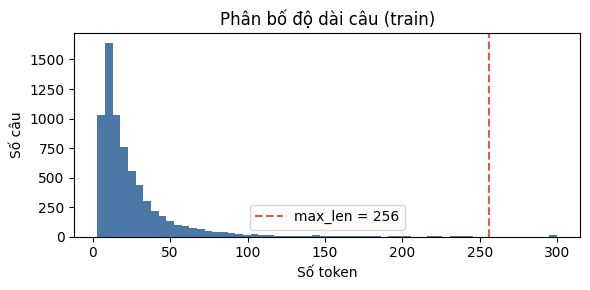

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def load_with_fallback(fn, name, **kw):
    # Phòng trường hợp phiên bản transformers cần trust_remote_code
    try:
        return fn(name, **kw)
    except Exception as e:
        print(f'(thử lại với trust_remote_code=True do lỗi {type(e).__name__})')
        return fn(name, trust_remote_code=True, **kw)

tokenizer = load_with_fallback(AutoTokenizer.from_pretrained, MODEL_NAME)
lens = np.array([len(x) for x in tokenizer(list(train_df[TEXT_COL]))['input_ids']])
print(f'Số token mỗi câu: trung vị {int(np.median(lens))}, 95% câu ≤ {int(np.percentile(lens, 95))}, '
      f'dài nhất {lens.max()}')
print(f'Tỉ lệ câu bị cắt bớt ở max_len = {MAX_LEN}: {(lens > MAX_LEN).mean() * 100:.1f}%')
print('Ví dụ tách token:', tokenizer.tokenize(train_df[TEXT_COL].iloc[0])[:20])

plt.figure(figsize=(6, 3))
plt.hist(np.clip(lens, 0, 300), bins=60, color='#4C78A8')
plt.axvline(MAX_LEN, color='#E45756', ls='--', label=f'max_len = {MAX_LEN}')
plt.xlabel('Số token'); plt.ylabel('Số câu'); plt.title('Phân bố độ dài câu (train)'); plt.legend()
plt.tight_layout(); plt.show()

## 6. Dataset và DataLoader
Dùng *padding động*: mỗi batch chỉ được pad tới độ dài câu dài nhất trong batch đó. Vì đa số câu ngắn, cách này giúp train nhanh hơn nhiều so với pad mọi câu về `max_len`, nhất là khi chạy trên CPU.

In [8]:
from torch.utils.data import Dataset, DataLoader

class TextDataset(Dataset):
    def __init__(self, df):
        self.ids = tokenizer(list(df[TEXT_COL]), truncation=True, max_length=MAX_LEN)['input_ids']
        self.labels = df['label'].tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.ids[i], self.labels[i]

def collate(batch):
    L = max(len(x) for x, _ in batch)
    ids = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return ids, att, torch.tensor([y for _, y in batch])

ds_train, ds_val, ds_test = TextDataset(train_df), TextDataset(val_df), TextDataset(test_df)
dl_val  = DataLoader(ds_val,  batch_size=BATCH_SIZE * 2, collate_fn=collate)
dl_test = DataLoader(ds_test, batch_size=BATCH_SIZE * 2, collate_fn=collate)
print(len(ds_train), len(ds_val), len(ds_test))

7011 997 1992


## 7. Các hàm huấn luyện và đánh giá

- **Mất cân bằng lớp:** lớp toxic chỉ chiếm khoảng 3,4% tập train (240/7.000), nên dùng *weighted cross-entropy*. Trọng số lớp toxic bằng tỉ lệ số câu không toxic trên số câu toxic (khoảng 28), giới hạn tối đa 10.
- **Chọn epoch tốt nhất:** theo **PR-AUC trên val**. Không chọn theo F1, vì val chỉ có 45 câu toxic nên F1 dao động mạnh giữa các epoch.
- **Ngưỡng phân loại:** chọn trên **val** sao cho F1 lớp toxic cao nhất, sau đó giữ nguyên ngưỡng này khi đánh giá trên test.

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve, cohen_kappa_score)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); out = []
    for ids, att, _ in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

def evaluate(y, p, th):
    yhat = (p >= th).astype(int)
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(y, yhat, labels=[0, 1]).ravel())
    return {'threshold': float(th),
            'accuracy': float(accuracy_score(y, yhat)),
            'precision_toxic': float(precision_score(y, yhat, zero_division=0)),
            'recall_toxic': float(recall_score(y, yhat, zero_division=0)),
            'f1_toxic': float(f1_score(y, yhat, zero_division=0)),
            'f1_macro': float(f1_score(y, yhat, average='macro', zero_division=0)),
            'pr_auc': float(average_precision_score(y, p)),
            'roc_auc': float(roc_auc_score(y, p)),
            'cohen_kappa': float(cohen_kappa_score(y, yhat)),
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
            'confusion_matrix': [[tn, fp], [fn, tp]]}

def train_one_seed(seed):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=g)
    model = load_with_fallback(AutoModelForSequenceClassification.from_pretrained, MODEL_NAME, num_labels=2).to(DEVICE)
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()

    n0, n1 = int((train_df.label == 0).sum()), int((train_df.label == 1).sum())
    pos_w = min(n0 / n1, MAX_POS_WEIGHT)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, pos_w], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = len(dl_train) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    print(f'Trọng số lớp toxic = {pos_w:.1f} | {len(dl_train)} batch/epoch')

    best_ap, best_state, best_ep, history, bad, t0 = -1, None, 0, [], 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot, n = 0.0, 0
        for step, (ids, att, y) in enumerate(dl_train, 1):
            ids, att, y = ids.to(DEVICE), att.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=ids, attention_mask=att).logits
            loss = loss_fn(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
            if ep == 1 and step == 20:
                per = (time.time() - t0) / 20
                print(f'  ~{per:.2f} giây/batch → ước tính {per * len(dl_train) / 60:.1f} phút/epoch, '
                      f'{per * total / 60:.1f} phút cho {EPOCHS} epoch')
        pv = predict_proba(model, dl_val)
        ap = average_precision_score(val_df.label, pv)
        th, f1 = best_threshold(val_df.label.values, pv)
        history.append({'epoch': ep, 'train_loss': tot / n, 'val_pr_auc': ap, 'val_best_f1': f1})
        print(f'  epoch {ep}: loss {tot / n:.4f} | val PR-AUC {ap:.3f} | val F1 tốt nhất {f1:.3f} '
              f'| {(time.time() - t0) / 60:.1f} phút')
        if ap > best_ap:
            best_ap, best_ep, bad = ap, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print('  dừng sớm (early stopping)'); break
    train_minutes = (time.time() - t0) / 60
    peak_vram = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == 'cuda' else None

    model.load_state_dict(best_state)
    pv = predict_proba(model, dl_val)
    th, _ = best_threshold(val_df.label.values, pv)
    pt = predict_proba(model, dl_test)
    return {'model': model, 'history': pd.DataFrame(history), 'threshold': th,
            'val': evaluate(val_df.label.values, pv, th),
            'test': evaluate(test_df.label.values, pt, th),
            'test_05': evaluate(test_df.label.values, pt, 0.5),
            'val_prob': pv, 'test_prob': pt, 'best_epoch': best_ep, 'epochs_ran': len(history),
            'train_minutes': train_minutes, 'peak_vram_train_gb': peak_vram}

## 8. Huấn luyện
Trên GPU mất vài phút cho mỗi seed. Trên CPU có thể mất 1–3 giờ; sau 20 batch đầu notebook sẽ in thời gian ước tính.

In [10]:
results, histories, probs, val_probs, thresholds = [], {}, {}, {}, {}
best_model, best_val_ap = None, -1
for seed in SEEDS:
    print(f'\n===== seed {seed} =====')
    r = train_one_seed(seed)
    model, th, rt = r['model'], r['threshold'], r['test']
    histories[seed], probs[seed], val_probs[seed], thresholds[seed] = r['history'], r['test_prob'], r['val_prob'], th
    results.append({'seed': seed, 'best_epoch': r['best_epoch'], 'epochs_ran': r['epochs_ran'],
                    'train_minutes': r['train_minutes'], 'peak_vram_train_gb': r['peak_vram_train_gb'],
                    'val': r['val'], 'test': rt, 'test_threshold_0.5': r['test_05']})
    print(f"  TEST (ngưỡng {th:.3f}): P {rt['precision_toxic']:.3f} | R {rt['recall_toxic']:.3f} | "
          f"F1 {rt['f1_toxic']:.3f} | PR-AUC {rt['pr_auc']:.3f} | TP {rt['tp']} FP {rt['fp']} FN {rt['fn']} | "
          f"epoch tốt nhất {r['best_epoch']} | {r['train_minutes']:.1f} phút")
    if r['val']['pr_auc'] > best_val_ap:
        if best_model is not None: del best_model
        best_model, best_val_ap, best_seed = model, r['val']['pr_auc'], seed
    del r, model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


===== seed 42 =====


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trọng số lớp toxic = 10.0 | 439 batch/epoch


... (5 outputs left out)

Trọng số lớp toxic = 10.0 | 439 batch/epoch
  ~0.13 giây/batch → ước tính 1.0 phút/epoch, 4.8 phút cho 5 epoch
  epoch 1: loss 0.4125 | val PR-AUC 0.556 | val F1 tốt nhất 0.707 | 1.0 phút
  epoch 2: loss 0.1969 | val PR-AUC 0.679 | val F1 tốt nhất 0.679 | 2.0 phút
  epoch 3: loss 0.1080 | val PR-AUC 0.699 | val F1 tốt nhất 0.694 | 2.9 phút
  epoch 4: loss 0.0409 | val PR-AUC 0.737 | val F1 tốt nhất 0.699 | 3.9 phút
  epoch 5: loss 0.0168 | val PR-AUC 0.753 | val F1 tốt nhất 0.714 | 4.9 phút
  TEST (ngưỡng 0.006): P 0.780 | R 0.800 | F1 0.790 | PR-AUC 0.758 | TP 64 FP 18 FN 16 | epoch tốt nhất 5 | 4.9 phút

===== seed 7 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trọng số lớp toxic = 10.0 | 439 batch/epoch
  ~0.13 giây/batch → ước tính 1.0 phút/epoch, 4.8 phút cho 5 epoch
  epoch 1: loss 0.4270 | val PR-AUC 0.616 | val F1 tốt nhất 0.673 | 1.0 phút
  epoch 2: loss 0.2500 | val PR-AUC 0.697 | val F1 tốt nhất 0.689 | 1.9 phút
  epoch 3: loss 0.1135 | val PR-AUC 0.714 | val F1 tốt nhất 0.714 | 2.9 phút
  epoch 4: loss 0.0446 | val PR-AUC 0.733 | val F1 tốt nhất 0.721 | 3.9 phút
  epoch 5: loss 0.0154 | val PR-AUC 0.699 | val F1 tốt nhất 0.721 | 4.9 phút
  TEST (ngưỡng 0.997): P 0.800 | R 0.600 | F1 0.686 | PR-AUC 0.815 | TP 48 FP 12 FN 32 | epoch tốt nhất 4 | 4.9 phút


## 9. Kết quả trên tập test

In [11]:
keys  = ['accuracy', 'precision_toxic', 'recall_toxic', 'f1_toxic', 'f1_macro', 'pr_auc', 'roc_auc', 'cohen_kappa',
         'tp', 'fp', 'fn', 'tn']
names = ['Accuracy', 'Precision (toxic)', 'Recall (toxic)', 'F1 (toxic)', 'Macro-F1', 'PR-AUC', 'ROC-AUC', "Cohen's Kappa",
         'TP', 'FP', 'FN', 'TN']

def summary_table(split):
    per = pd.DataFrame([{n: r[split][k] for k, n in zip(keys, names)} for r in results],
                       index=[f'seed {r["seed"]}' + (' (nộp)' if r['seed'] == best_seed else '') for r in results])
    tab = per.copy()
    if len(results) > 1:
        tab.loc['Trung bình'] = per.mean()
        tab.loc['Độ lệch chuẩn'] = per.std(ddof=0)
    return per, tab

show = lambda t: display(t) if 'display' in globals() else print(t)
per_seed, table = summary_table('test')
print(f'TEST, ngưỡng chọn trên val (seed nộp = {best_seed}, chọn theo PR-AUC val cao nhất):'); show(table.round(4))
per_seed_05, table_05 = summary_table('test_threshold_0.5')
print('TEST, ngưỡng cố định 0.5 (để so sánh):'); show(table_05.round(4))
per_seed_val, table_val = summary_table('val')
print('VAL (ngưỡng tối ưu trên chính val):'); show(table_val.round(4))

seed_cfg = pd.DataFrame([{'Ngưỡng (chọn trên val)': thresholds[r['seed']], 'Epoch tốt nhất': r['best_epoch'],
                          'Số epoch đã chạy': r['epochs_ran'], 'Thời gian train (phút)': r['train_minutes'],
                          'VRAM đỉnh khi train (GB)': r['peak_vram_train_gb']} for r in results],
                        index=[f'seed {r["seed"]}' for r in results])
print('Cấu hình/chi phí từng seed:'); show(seed_cfg.round(3))

summ_of = lambda per: {k: {'mean': float(per[n].mean()), 'std': float(per[n].std(ddof=0))} for k, n in zip(keys, names)}
json.dump({'config': {k: globals()[k] for k in ['MODEL_NAME', 'INPUT_MODE', 'NORMALIZE_TEENCODE', 'SEEDS', 'EPOCHS', 'BATCH_SIZE', 'LR',
                                                'WARMUP', 'MAX_LEN', 'MAX_POS_WEIGHT', 'PATIENCE']},
           'env': ENV, 'best_seed': int(best_seed), 'per_seed': results,
           'test_summary': summ_of(per_seed), 'test_threshold_0.5_summary': summ_of(per_seed_05),
           'val_summary': summ_of(per_seed_val)},
          open(os.path.join(OUT_DIR, 'metrics.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
table.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_test.csv'), encoding='utf-8-sig')
table_05.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_test_nguong_0.5.csv'), encoding='utf-8-sig')
table_val.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_val.csv'), encoding='utf-8-sig')
seed_cfg.round(4).to_csv(os.path.join(OUT_DIR, 'cau_hinh_tung_seed.csv'), encoding='utf-8-sig')
print('Đã lưu metrics.json, ket_qua_test.csv, ket_qua_test_nguong_0.5.csv, ket_qua_val.csv, cau_hinh_tung_seed.csv vào', OUT_DIR)

TEST, ngưỡng chọn trên val (seed nộp = 13, chọn theo PR-AUC val cao nhất):
               Accuracy  Precision (toxic)  Recall (toxic)  F1 (toxic)  \
seed 42          0.9784             0.7534          0.6875      0.7190   
seed 13 (nộp)    0.9829             0.7805          0.8000      0.7901   
seed 7           0.9779             0.8000          0.6000      0.6857   
Trung bình       0.9798             0.7780          0.6958      0.7316   
Độ lệch chuẩn    0.0023             0.0191          0.0819      0.0436   

               Macro-F1  PR-AUC  ROC-AUC  Cohen's Kappa       TP       FP  \
seed 42          0.8539  0.7481   0.9744         0.7078  55.0000  18.0000   
seed 13 (nộp)    0.8906  0.7580   0.9399         0.7812  64.0000  18.0000   
seed 7           0.8371  0.8152   0.9796         0.6745  48.0000  12.0000   
Trung bình       0.8605  0.7738   0.9646         0.7212  55.6667  16.0000   
Độ lệch chuẩn    0.0223  0.0295   0.0176         0.0446   6.5490   2.8284   

                 

### Lưu điểm dự đoán val/test của mọi seed
`val_scores_all_seeds.csv` và `test_scores_all_seeds.csv` (cột `score_seed<seed>` là xác suất lớp toxic). Dùng để:
- kết hợp với SVM (ensemble, định tuyến 2 tầng): trọng số và ngưỡng phải chọn trên **val**, nên cần điểm val;
- kiểm định McNemar giữa PhoBERT và mô hình khác (dùng cột `pred` của `results/predictions/phobert.csv`).

In [12]:
val_scores = pd.DataFrame({'review_id': val_df.review_id, 'label': val_df.label,
                           **{f'score_seed{s}': val_probs[s] for s in SEEDS}})
test_scores = pd.DataFrame({'review_id': test_df.review_id, 'label': test_df.label,
                            **{f'score_seed{s}': probs[s] for s in SEEDS}})
val_scores.to_csv(os.path.join(OUT_DIR, 'val_scores_all_seeds.csv'), index=False, encoding='utf-8')
test_scores.to_csv(os.path.join(OUT_DIR, 'test_scores_all_seeds.csv'), index=False, encoding='utf-8')
json.dump({'best_seed': int(best_seed), 'thresholds': {int(s): thresholds[s] for s in SEEDS}},
          open(os.path.join(OUT_DIR, 'thresholds.json'), 'w', encoding='utf-8'), indent=2)
print('Đã lưu val_scores_all_seeds.csv, test_scores_all_seeds.csv, thresholds.json vào', OUT_DIR)

Đã lưu val_scores_all_seeds.csv, test_scores_all_seeds.csv, thresholds.json vào ./results/phobert_v2


### Confusion matrix và đường Precision-Recall (seed tốt nhất)

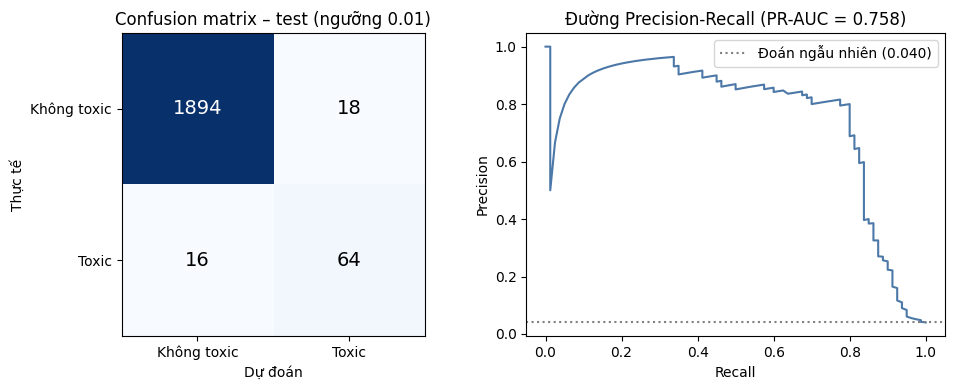

In [13]:
s = best_seed
pt, th = probs[s], thresholds[s]
cm = confusion_matrix(test_df.label, (pt >= th).astype(int), labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Không toxic', 'Toxic']); ax.set_yticks([0, 1], ['Không toxic', 'Toxic'])
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title(f'Confusion matrix – test (ngưỡng {th:.2f})')

prec, rec, _ = precision_recall_curve(test_df.label, pt)
axes[1].plot(rec, prec, color='#4C78A8')
axes[1].axhline(test_df.label.mean(), color='gray', ls=':', label=f'Đoán ngẫu nhiên ({test_df.label.mean():.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title(f'Đường Precision-Recall (PR-AUC = {average_precision_score(test_df.label, pt):.3f})')
axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'confusion_matrix_pr_curve.png'), dpi=150); plt.show()

### Đường học (learning curve)

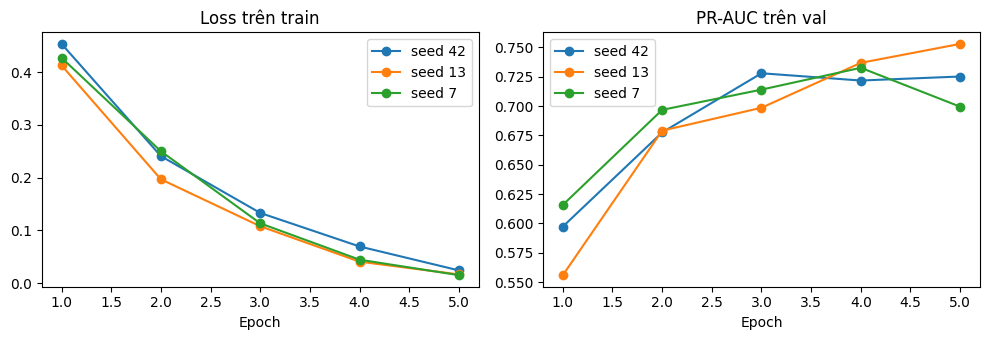

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for s, h in histories.items():
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=f'seed {s}')
    axes[1].plot(h.epoch, h.val_pr_auc, marker='o', label=f'seed {s}')
axes[0].set_title('Loss trên train'); axes[1].set_title('PR-AUC trên val')
for a in axes: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'learning_curve.png'), dpi=150); plt.show()

## 10. Phân tích lỗi
- **Bỏ sót (FN):** câu toxic nhưng mô hình đoán không toxic.
- **Báo nhầm (FP):** câu không toxic nhưng mô hình đoán toxic.

In [15]:
pred = test_df.copy()
pred['prob_toxic'] = probs[best_seed]
pred['pred'] = (pred.prob_toxic >= thresholds[best_seed]).astype(int)
pred.to_csv(os.path.join(OUT_DIR, 'predictions_test.csv'), index=False, encoding='utf-8-sig')
err = pred[pred.pred != pred.label].copy()
err['loai_loi'] = np.where(err.label == 1, 'Bỏ sót (FN)', 'Báo nhầm (FP)')
err.sort_values('prob_toxic', ascending=False).to_csv(os.path.join(OUT_DIR, 'errors_test.csv'), index=False, encoding='utf-8-sig')
print(err.loai_loi.value_counts().to_string(), '\n')
pd.set_option('display.max_colwidth', 160)
show = err[['loai_loi', 'prob_toxic', 'noi_dung_goc']].sort_values(['loai_loi', 'prob_toxic'], ascending=[True, False]).head(20)
display(show) if 'display' in globals() else print(show)

loai_loi
Báo nhầm (FP)    18
Bỏ sót (FN)      16 

           loai_loi  prob_toxic  \
1766  Báo nhầm (FP)    0.998910   
713   Báo nhầm (FP)    0.998533   
386   Báo nhầm (FP)    0.998460   
280   Báo nhầm (FP)    0.998364   
271   Báo nhầm (FP)    0.998190   
1542  Báo nhầm (FP)    0.998118   
354   Báo nhầm (FP)    0.997993   
679   Báo nhầm (FP)    0.997888   
994   Báo nhầm (FP)    0.997726   
1065  Báo nhầm (FP)    0.997493   
194   Báo nhầm (FP)    0.997048   
261   Báo nhầm (FP)    0.995095   
761   Báo nhầm (FP)    0.993372   
621   Báo nhầm (FP)    0.989672   
1592  Báo nhầm (FP)    0.267313   
1457  Báo nhầm (FP)    0.176601   
867   Báo nhầm (FP)    0.040163   
1709  Báo nhầm (FP)    0.008745   
1963    Bỏ sót (FN)    0.001235   
207     Bỏ sót (FN)    0.000809   

                                                                                                                                                         noi_dung_goc  
1766                                         

### Kiểm tra các review ID mà báo cáo đang trích dẫn
Báo cáo (mục 3.3.2) dùng một số câu làm ví dụ cho phần phân tích lỗi. Ô dưới cho biết PhoBERT của seed nộp dự đoán thế nào với từng câu (đúng/sai, xác suất), để sửa lại phần phân tích cho khớp. Có thể thêm ID khác vào `REPORT_IDS`.

In [17]:
REPORT_IDS = [56417329, 56979900, 59177191, 59425217, 55182406, 51346530, 58055724]
ids = set(map(str, REPORT_IDS))
chk_ids = pred[pred.review_id.astype(str).isin(ids)][['review_id', 'label', 'prob_toxic', 'pred', 'noi_dung_goc']].copy()
chk_ids['ket_qua'] = np.select([(chk_ids.label == 1) & (chk_ids.pred == 1), (chk_ids.label == 0) & (chk_ids.pred == 0),
                                chk_ids.label == 1], ['Đúng (TP)', 'Đúng (TN)', 'Sai: bỏ sót (FN)'], 'Sai: báo nhầm (FP)')
missing = ids - set(chk_ids.review_id.astype(str))
if missing: print('Không thấy trong test.csv:', sorted(missing))
chk_ids.to_csv(os.path.join(OUT_DIR, 'bang_kiem_tra_review_id.csv'), index=False, encoding='utf-8-sig')
display(chk_ids[['review_id', 'label', 'pred', 'prob_toxic', 'ket_qua', 'noi_dung_goc']])

Không thấy trong test.csv: ['55182406']


,review_id,label,pred,prob_toxic,ket_qua,noi_dung_goc
45,59425217,1,1,0.997977,Đúng (TP),Giới thiệu có ngăn đông mềm. Mà quá tệ. Đồ để 3 ngày đã bị hư. Báo lên hãng xún thì nói ngăn đó là ngăn rã đông mềm.OMG. Chứ ko phải ngăn đông mềm. Thật sư ...
77,51346530,1,1,0.997783,Đúng (TP),"Quạt ngăn đông kêu khọt khọt to, tiếng ga bơm lên thì kêu e e ũng to nốt nhưng khi gọi nv của HÃNG TOSHIBA tới thì nói TIẾNG NÀY LÀ BÌNH THƯỜNG, tôi kh biết..."
199,56417329,1,1,0.998339,Đúng (TP),Không nên mua máy của 1 nhãn hàng lớn mà thiếu chuyên nghiệp từ nhân viên đến kiểm tra và cách trả lời của hãng với khách hàng. Lừa những người không có am ...
535,56979900,1,1,0.998774,Đúng (TP),Nhân viên lắp đặt nói chuyện tào lao. Tôi mua máy thương hiệu Nhật cho Ba Mẹ tôi nhưng nhân viên đem tới lắp đặt lại nói là hiệu Việt Nam. Nhân viên ĐMX có ...
541,59177191,1,0,0.000477,Sai: bỏ sót (FN),"Tệ vl, 20.000 mah mà sạc iphone 15promax chưa đc 2 lần. Thua luônẢo ma canada"
693,58055724,1,1,0.998683,Đúng (TP),nấu cơm để trong ngày cơm cũng bị thiêu đem lên bảo hành hết 15 ngày hãng nói không bị gì đem trả về khuyên mọi người né cái hiệu này nha


## 11. Xuất file nộp TV4
Theo `QUY_UOC_FILE_DU_DOAN.md`:
- `results/predictions/phobert.csv`: đúng 4 cột `review_id, label, score, pred`, khớp toàn bộ số dòng của `data/test.csv`. `score` là xác suất lớp toxic (`softmax(logits)[:, 1]`), `pred = (score >= threshold)`.
- `results/predictions/phobert_info.json`: ngưỡng, nơi chọn ngưỡng (`val`), siêu tham số, seed tốt nhất.

Khi chạy nhiều seed, file nộp lấy **seed có PR-AUC trên val cao nhất** (chọn trên val, không chọn theo test). Trung bình ± độ lệch chuẩn qua các seed được ghi vào `ghi_chu` và `metrics.json` để đưa vào báo cáo.


In [18]:
score = probs[best_seed].astype(np.float64)   # float64: `score >= threshold` không đổi sau khi ghi/đọc lại CSV
th = float(thresholds[best_seed])
sub = pd.DataFrame({'review_id': test_df['review_id'], 'label': test_df['label'],
                    'score': score, 'pred': (score >= th).astype(int)})
sub.to_csv(os.path.join(PRED_DIR, 'phobert.csv'), index=False, encoding='utf-8')

rt = next(r['test'] for r in results if r['seed'] == best_seed)
h = histories[best_seed]
pos_w = min((train_df.label == 0).sum() / (train_df.label == 1).sum(), MAX_POS_WEIGHT)
summ = {k: (per_seed[n].mean(), per_seed[n].std(ddof=0)) for k, n in zip(keys, names)}
info = {
    'nguoi_phu_trach': 'TV3',
    'mo_hinh': 'PhoBERT (vinai/phobert-base-v2)',
    'threshold': th,
    'chon_nguong_tren': 'val',
    'sieu_tham_so': {
        'backbone': 'vinai/phobert-base-v2',
        'training_mode': f'End-to-End Fine-Tuning (AdamW, {DEVICE.type.upper()})',
        'epochs_toi_da': EPOCHS, 'epoch_tot_nhat': int(h.loc[h.val_pr_auc.idxmax(), 'epoch']),
        'early_stopping_patience': PATIENCE,
        'lr': LR, 'warmup': WARMUP, 'batch_size': BATCH_SIZE, 'max_len': MAX_LEN,
        'loss': f'CrossEntropyLoss(weights=[1.0, {pos_w:.1f}])',
        'input_mode': INPUT_MODE, 'normalize_teencode': NORMALIZE_TEENCODE,
    },
    'random_seed': int(best_seed),
    'ghi_chu': (f'Fine-tune PhoBERT với các seed {SEEDS}; nộp seed {best_seed} (PR-AUC val cao nhất). '
                f"Test trung bình qua các seed: F1 toxic {summ['f1_toxic'][0]:.4f} ± {summ['f1_toxic'][1]:.4f}, "
                f"PR-AUC {summ['pr_auc'][0]:.4f} ± {summ['pr_auc'][1]:.4f}."),
    'metrics_test': {k: (int(rt[k]) if k in ('tp', 'fp', 'fn', 'tn') else float(rt[k])) for k in keys},
}
json.dump(info, open(os.path.join(PRED_DIR, 'phobert_info.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print(json.dumps(info, ensure_ascii=False, indent=2))

{
  "nguoi_phu_trach": "TV3",
  "threshold": 0.0060386634431779385,
  "chon_nguong_tren": "val",
  "sieu_tham_so": {
    "backbone": "vinai/phobert-base-v2",
    "training_mode": "End-to-End Fine-Tuning (AdamW, CUDA)",
    "epochs_toi_da": 5,
    "epoch_tot_nhat": 5,
    "early_stopping_patience": 2,
    "lr": 2e-05,
    "warmup": 0.1,
    "batch_size": 16,
    "max_len": 256,
    "loss": "CrossEntropyLoss(weights=[1.0, 10.0])",
    "input_mode": "pyvi",
    "normalize_teencode": true
  },
  "random_seed": 13,
  "ghi_chu": "Fine-tune PhoBERT với các seed [42, 13, 7]; nộp seed 13 (PR-AUC val cao nhất). Test trung bình qua các seed: F1 toxic 0.7316 ± 0.0436, PR-AUC 0.7738 ± 0.0295.",
  "metrics_test": {
    "accuracy": 0.9829317269076305,
    "precision_toxic": 0.7804878048780488,
    "recall_toxic": 0.8,
    "f1_toxic": 0.7901234567901234,
    "f1_macro": 0.8906137953757001,
    "pr_auc": 0.7580213217948435,
    "roc_auc": 0.9399156642259414,
    "cohen_kappa": 0.7812290040828983,
    "

In [19]:
# Tự kiểm tra theo mục 3 của quy ước (giống `python 4_model_evaluation.py --check results/predictions/phobert.csv`)
chk = pd.read_csv(os.path.join(PRED_DIR, 'phobert.csv'))
inf = json.load(open(os.path.join(PRED_DIR, 'phobert_info.json'), encoding='utf-8'))
errs = []
if list(chk.columns) != ['review_id', 'label', 'score', 'pred']: errs.append(f'Sai cột: {list(chk.columns)}')
if len(chk) != len(test_df) or chk.review_id.duplicated().any(): errs.append('Số dòng sai hoặc review_id bị lặp')
if set(chk.review_id) != set(test_df.review_id): errs.append('review_id không khớp với test.csv')
if chk.isnull().any().any() or not np.isfinite(chk.score).all(): errs.append('Có ô trống hoặc score không hữu hạn')
m = chk.set_index('review_id').loc[test_df.review_id]
if (m.label.values != test_df.label.values).any(): errs.append('label không khớp với test.csv')
n_bad = ((chk.score >= inf['threshold']).astype(int) != chk.pred).sum()
if n_bad: errs.append(f'{n_bad} dòng pred không khớp score >= threshold')
print('HỢP LỆ' if not errs else 'LỖI:\n- ' + '\n- '.join(errs))

HỢP LỆ


## 12. Thử mô hình với câu tự nhập

In [20]:
def predict_text(texts, model=best_model, th=thresholds[best_seed]):
    seg = [ViTokenizer.tokenize(normalize(t).lower()) if INPUT_MODE == 'tien_xu_ly' else segment(t) for t in texts]
    enc = tokenizer(seg, truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt')
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(**{k: v.to(DEVICE) for k, v in enc.items() if k in ('input_ids', 'attention_mask')}).logits.float(), -1)[:, 1].cpu().numpy()
    for t, pi in zip(texts, p):
        print(f"{'TOXIC     ' if pi >= th else 'không toxic'} ({pi:.3f})  {t}")

predict_text([
    'Máy chạy êm, giao hàng nhanh, rất hài lòng',
    'Sản phẩm quá tệ, bảo hành chậm, không nên mua',
    'Bọn bán hàng lừa đảo, hàng đểu mà giá cắt cổ',
    'Gọi tổng đài cả ngày đéo ai nghe máy',
])

không toxic (0.000)  Máy chạy êm, giao hàng nhanh, rất hài lòng
không toxic (0.000)  Sản phẩm quá tệ, bảo hành chậm, không nên mua
TOXIC      (0.999)  Bọn bán hàng lừa đảo, hàng đểu mà giá cắt cổ
TOXIC      (0.999)  Gọi tổng đài cả ngày đéo ai nghe máy


## 13. Lưu mô hình
Mô hình được lưu vào `results/phobert_v2/best_model`. Có thể nạp lại bằng `AutoModelForSequenceClassification.from_pretrained('results/phobert_v2/best_model')`. Khi dùng lại, nhớ tách từ câu mới bằng hàm `segment()` ở mục 4.

In [21]:
if SAVE_MODEL:
    path = os.path.join(OUT_DIR, 'best_model')
    best_model.save_pretrained(path); tokenizer.save_pretrained(path)
    json.dump({'threshold': thresholds[best_seed], 'max_len': MAX_LEN, 'seed': best_seed,
               'input_mode': INPUT_MODE, 'normalize_teencode': NORMALIZE_TEENCODE},
              open(os.path.join(path, 'threshold.json'), 'w'))
    print('Đã lưu mô hình vào', os.path.abspath(path))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình vào /content/results/phobert_v2/best_model


## 14. Chi phí tính toán
Đo trên seed được nộp, để điền phần "đánh đổi tài nguyên" (RQ3) của báo cáo:
- **Số tham số, dung lượng mô hình** (thư mục `best_model`).
- **Thời gian train và VRAM đỉnh khi train** của từng seed (đo trong lúc train ở mục 8).
- **Tách từ (pyvi):** thời gian trung bình mỗi câu.
- **Suy luận GPU:** thời gian dự đoán toàn bộ 2.000 câu test (batch 32, fp16), số câu/giây, VRAM đỉnh.
- **Suy luận CPU:** độ trễ trung bình mỗi câu với batch 1 (giống cách gọi API từng bình luận), đo trên `N_CPU_LATENCY` câu test ngẫu nhiên.

Kết quả lưu vào `results/phobert_v2/cost.json`.

In [22]:
import copy

cost = {'so_tham_so': int(sum(p.numel() for p in best_model.parameters()))}
mdir = os.path.join(OUT_DIR, 'best_model')
if os.path.isdir(mdir):
    cost['dung_luong_mo_hinh_mb'] = sum(os.path.getsize(os.path.join(mdir, f)) for f in os.listdir(mdir)) / 2**20
else:
    cost['dung_luong_mo_hinh_mb'] = sum(p.numel() * p.element_size() for p in best_model.parameters()) / 2**20
cost['thoi_gian_train_phut'] = {int(r['seed']): r['train_minutes'] for r in results}
cost['vram_dinh_khi_train_gb'] = {int(r['seed']): r['peak_vram_train_gb'] for r in results}

# 1) Tách từ bằng pyvi
texts = test_df['noi_dung_goc'].tolist()
t = time.perf_counter(); _ = [segment(x) for x in texts]; s = time.perf_counter() - t
cost['tach_tu_ms_moi_cau'] = s / len(texts) * 1000

# 2) Suy luận GPU trên toàn bộ test
if DEVICE.type == 'cuda':
    predict_proba(best_model, dl_val)                      # khởi động (warm-up)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.perf_counter(); predict_proba(best_model, dl_test); torch.cuda.synchronize()
    s = time.perf_counter() - t
    cost.update({'gpu': torch.cuda.get_device_name(0), 'gpu_batch_size': BATCH_SIZE * 2, 'gpu_fp16': USE_AMP,
                 'gpu_test_giay': s, 'gpu_cau_moi_giay': len(ds_test) / s, 'gpu_ms_moi_cau': s / len(ds_test) * 1000,
                 'gpu_vram_suy_luan_gb': torch.cuda.max_memory_allocated() / 2**30})

# 3) Suy luận CPU, batch 1
if MEASURE_CPU_LATENCY:
    cpu_model = copy.deepcopy(best_model).float().to('cpu').eval()
    idx = np.random.RandomState(0).choice(len(ds_test), size=min(N_CPU_LATENCY, len(ds_test)), replace=False)
    with torch.no_grad():
        for i in idx[:5]:
            cpu_model(input_ids=torch.tensor([ds_test.ids[i]]))          # warm-up
        t = time.perf_counter()
        for i in idx:
            cpu_model(input_ids=torch.tensor([ds_test.ids[i]]))
        s = time.perf_counter() - t
    cost.update({'cpu_so_luong_dung': torch.get_num_threads(), 'cpu_so_cau_do': int(len(idx)),
                 'cpu_ms_moi_cau': s / len(idx) * 1000, 'cpu_cau_moi_giay': len(idx) / s})
    del cpu_model

json.dump(cost, open(os.path.join(OUT_DIR, 'cost.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print(json.dumps(cost, ensure_ascii=False, indent=2))

{
  "so_tham_so": 134999810,
  "dung_luong_mo_hinh_mb": 516.9448766708374,
  "thoi_gian_train_phut": {
    "42": 5.244119576613108,
    "13": 4.879935733477274,
    "7": 4.874565653006235
  },
  "vram_dinh_khi_train_gb": {
    "42": 3.8264427185058594,
    "13": 4.845277786254883,
    "7": 4.85704231262207
  },
  "tach_tu_ms_moi_cau": 0.42872958232932945,
  "gpu": "Tesla T4",
  "gpu_batch_size": 32,
  "gpu_fp16": true,
  "gpu_test_giay": 2.736906480000016,
  "gpu_cau_moi_giay": 727.8290341875285,
  "gpu_ms_moi_cau": 1.3739490361445865,
  "gpu_vram_suy_luan_gb": 1.3972554206848145,
  "cpu_so_luong_dung": 1,
  "cpu_so_cau_do": 200,
  "cpu_ms_moi_cau": 122.40616317499985,
  "cpu_cau_moi_giay": 8.169523282666207
}


## 15. Tổng hợp số liệu cho báo cáo
Gom toàn bộ số liệu PhoBERT cần điền vào báo cáo (bảng kết quả, cấu hình, môi trường, chi phí, phân tích lỗi) vào **một file** `results/phobert_v2/so_lieu_bao_cao.md` (và bản `.json`).

In [23]:
def to_md(df):
    try: return df.to_markdown()
    except ImportError: return df.to_string()      # thiếu thư viện tabulate

pct = lambda v: f'{v * 100:.2f}%'
rt = next(r['test'] for r in results if r['seed'] == best_seed)
sm = {k: (per_seed[n].mean(), per_seed[n].std(ddof=0)) for k, n in zip(keys, names)}
h = histories[best_seed]
pos_w = min((train_df.label == 0).sum() / (train_df.label == 1).sum(), MAX_POS_WEIGHT)
n_err = err.loai_loi.value_counts().to_dict()

L = ['# Số liệu PhoBERT cho báo cáo', '',
     '## Bảng kết quả trên tập test (2.000 câu, 75 toxic)', '',
     '| Dòng | Accuracy | Precision | Recall | F1 (toxic) | Macro-F1 | PR-AUC | ROC-AUC | Kappa | TP | FP | FN | TN |',
     '|---|---|---|---|---|---|---|---|---|---|---|---|---|',
     f"| PhoBERT, seed nộp {best_seed} (ngưỡng {thresholds[best_seed]:.3f}) | {pct(rt['accuracy'])} | {pct(rt['precision_toxic'])} | "
     f"{pct(rt['recall_toxic'])} | {rt['f1_toxic']:.4f} | {rt['f1_macro']:.4f} | {rt['pr_auc']:.4f} | {rt['roc_auc']:.4f} | "
     f"{rt['cohen_kappa']:.4f} | {rt['tp']} | {rt['fp']} | {rt['fn']} | {rt['tn']} |"]
if len(results) > 1:
    L.append(f"| PhoBERT, trung bình ± độ lệch chuẩn {len(results)} seed | "
             + ' | '.join([f"{sm[k][0] * 100:.2f} ± {sm[k][1] * 100:.2f}%" for k in ('accuracy', 'precision_toxic', 'recall_toxic')]
                          + [f"{sm[k][0]:.4f} ± {sm[k][1]:.4f}" for k in ('f1_toxic', 'f1_macro', 'pr_auc', 'roc_auc', 'cohen_kappa')]
                          + [f"{sm[k][0]:.1f}" for k in ('tp', 'fp', 'fn', 'tn')]) + ' |')
L += ['', '## Kết quả từng seed (test)', '', to_md(table.round(4)),
      '', '## Cấu hình huấn luyện', '',
      f'- Backbone: `{MODEL_NAME}` ({cost["so_tham_so"] / 1e6:.0f} triệu tham số, {cost["dung_luong_mo_hinh_mb"]:.0f} MB)',
      f'- Đầu vào: INPUT_MODE = `{INPUT_MODE}` (chuẩn hoá NFC, tách chữ dính, teencode = {NORMALIZE_TEENCODE}, tách từ pyvi; giữ chữ hoa, dấu câu, stopword)',
      f'- Fine-tune toàn bộ mô hình, AdamW (lr {LR}, weight decay 0.01), warmup tuyến tính {int(WARMUP * 100)}%, gradient clipping 1.0, fp16 = {USE_AMP}',
      f'- Weighted Cross-Entropy, trọng số [1.0, {pos_w:.1f}] (tỉ lệ thật ≈ {(train_df.label == 0).sum() / (train_df.label == 1).sum():.1f}, giới hạn {MAX_POS_WEIGHT})',
      f'- Batch {BATCH_SIZE}, max_len {MAX_LEN}, tối đa {EPOCHS} epoch, dừng sớm theo PR-AUC val (patience {PATIENCE})',
      f'- Seed: {SEEDS}; seed nộp {best_seed} (PR-AUC val cao nhất), epoch tốt nhất {int(h.loc[h.val_pr_auc.idxmax(), "epoch"])}',
      f'- Ngưỡng chọn trên val (F1 toxic cao nhất): ' + ', '.join(f'seed {s}: {thresholds[s]:.3f}' for s in SEEDS),
      '', '## Môi trường', '', *[f'- {k}: {v}' for k, v in ENV.items()],
      '', '## Chi phí tính toán', '', *[f'- {k}: {v}' for k, v in cost.items()],
      '', '## Phân tích lỗi (seed nộp)', '',
      f"- Bỏ sót (FN): {n_err.get('Bỏ sót (FN)', 0)} câu, báo nhầm (FP): {n_err.get('Báo nhầm (FP)', 0)} câu (chi tiết: errors_test.csv)",
      f'- Review ID báo cáo đang trích dẫn: xem bang_kiem_tra_review_id.csv']
text = '\n'.join(L)
open(os.path.join(OUT_DIR, 'so_lieu_bao_cao.md'), 'w', encoding='utf-8').write(text)
json.dump({'best_seed': int(best_seed), 'test_seed_nop': rt, 'test_trung_binh': summ_of(per_seed),
           'thresholds': {int(s): thresholds[s] for s in SEEDS}, 'env': ENV, 'cost': cost,
           'so_loi': n_err}, open(os.path.join(OUT_DIR, 'so_lieu_bao_cao.json'), 'w', encoding='utf-8'),
          ensure_ascii=False, indent=2)
print(text)

# Số liệu PhoBERT cho báo cáo

## Bảng kết quả trên tập test (2.000 câu, 75 toxic)

| Dòng | Accuracy | Precision | Recall | F1 (toxic) | Macro-F1 | PR-AUC | ROC-AUC | Kappa | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| PhoBERT, seed nộp 13 (ngưỡng 0.006) | 98.29% | 78.05% | 80.00% | 0.7901 | 0.8906 | 0.7580 | 0.9399 | 0.7812 | 64 | 18 | 16 | 1894 |
| PhoBERT, trung bình ± độ lệch chuẩn 3 seed | 97.98 ± 0.23% | 77.80 ± 1.91% | 69.58 ± 8.19% | 0.7316 ± 0.0436 | 0.8605 ± 0.0223 | 0.7738 ± 0.0295 | 0.9646 ± 0.0176 | 0.7212 ± 0.0446 | 55.7 | 16.0 | 24.3 | 1896.0 |

## Kết quả từng seed (test)

|               |   Accuracy |   Precision (toxic) |   Recall (toxic) |   F1 (toxic) |   Macro-F1 |   PR-AUC |   ROC-AUC |   Cohen's Kappa |      TP |      FP |      FN |        TN |
|:--------------|-----------:|--------------------:|-----------------:|-------------:|-----------:|---------:|----------:|----------------:|--------:|--------:|--------:|----------:|
| see

## 16. Nén kết quả để tải về
Tạo `results_phobert_v2.zip` chứa thư mục `results/` (file nộp TV4 và kết quả chi tiết), **trừ** `best_model/` (khoảng 540 MB, không nên đưa vào git). Tải file zip ở tab Output rồi **giải nén vào thư mục gốc repo**: file sẽ nằm đúng ở `results/predictions/phobert.csv` và `results/phobert_v2/`.

In [24]:
import zipfile

zip_name = "results_phobert_v2.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for d in (OUT_DIR, PRED_DIR):
        for root, dirs, files in os.walk(d):
            dirs[:] = [x for x in dirs if x != "best_model"]
            for f in files:
                p = os.path.join(root, f)
                z.write(p, os.path.relpath(p, ROOT))
    print("Các file đã nén:")
    for item in z.namelist():
        print(f" - {item}")

print(f"\n🎉 Đã tạo thành công file nén: {os.path.abspath(zip_name)}")

# Tự động tải về máy nếu đang chạy trên Google Colab
try:
    from google.colab import files
    print("⬇️ Đang tự động tải results_phobert_v2.zip về máy...")
    files.download(zip_name)
except Exception:
    pass


Các file đã nén:
 - results/phobert_v2/test_scores_all_seeds.csv
 - results/phobert_v2/ket_qua_val.csv
 - results/phobert_v2/thresholds.json
 - results/phobert_v2/ket_qua_test_nguong_0.5.csv
 - results/phobert_v2/errors_test.csv
 - results/phobert_v2/cost.json
 - results/phobert_v2/confusion_matrix_pr_curve.png
 - results/phobert_v2/val_scores_all_seeds.csv
 - results/phobert_v2/learning_curve.png
 - results/phobert_v2/predictions_test.csv
 - results/phobert_v2/so_lieu_bao_cao.json
 - results/phobert_v2/ket_qua_test.csv
 - results/phobert_v2/so_lieu_bao_cao.md
 - results/phobert_v2/bang_kiem_tra_review_id.csv
 - results/phobert_v2/cau_hinh_tung_seed.csv
 - results/phobert_v2/metrics.json
 - results/predictions/phobert.csv
 - results/predictions/phobert_info.json

🎉 Đã tạo thành công file nén: /content/results_phobert_v2.zip
⬇️ Đang tự động tải results_phobert_v2.zip về máy...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>